# Perfilado de Datos - Conteos Censales de Participación Ciudadana

Revisión de calidad, cobertura y distribuciones de los datasets consolidados en `DATA/PREPROCESSED/`.
Requiere haber ejecutado `01_ingesta_datos.ipynb`.

## 1. Librerías

In [1]:
import gc

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

## 2. Rutas del proyecto

In [2]:
ROOT = Path().resolve().parent
DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

PQ_FEDERAL = DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet"
PQ_PJ2025 = DIR_PREPROCESSED / "conteos_pj2025.parquet"
PQ_ANTICIPADO = DIR_PREPROCESSED / "voto_anticipado_2024.parquet"
PQ_PRISION = DIR_PREPROCESSED / "prision_preventiva_2024.parquet"

print(f"Raiz del proyecto: {ROOT}")
print(f"Preprocesados:     {DIR_PREPROCESSED}")

Raiz del proyecto: C:\Users\jonat\Documentos_Locales\Repo INE HACKATHON\INE_HACKATHON
Preprocesados:     C:\Users\jonat\Documentos_Locales\Repo INE HACKATHON\INE_HACKATHON\DATA\PREPROCESSED


## 3. Configuración de visualización

Paleta fija para todas las gráficas del notebook: azul para una sola serie, azul/naranja para sexo
y una escala de un solo tono (azul) para mapas de calor.

In [3]:
AZUL = "#2a78d6"
NARANJA = "#eb6834"
TEXTO = "#52514e"
REJILLA = "#e1e0d9"
CMAP_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": REJILLA,
    "axes.labelcolor": TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": REJILLA,
    "grid.linewidth": 0.6,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "lines.linewidth": 2,
    "lines.markersize": 7,
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 4. Inventario de archivos Parquet

Filas, columnas y tamaño de cada archivo generado en la ingesta.

In [4]:
for f in [PQ_FEDERAL, PQ_PJ2025, PQ_ANTICIPADO, PQ_PRISION]:
    meta = pq.ParquetFile(f).metadata
    print(f"{f.name:36s} {meta.num_rows:>12,} filas  {meta.num_columns:>3} cols  {f.stat().st_size / 1024**2:>7.1f} MB")

conteos_federal_2009_2024.parquet      54,872,712 filas   16 cols    184.3 MB
conteos_pj2025.parquet                  9,835,254 filas   16 cols     76.0 MB
voto_anticipado_2024.parquet                3,449 filas    8 cols      0.0 MB
prision_preventiva_2024.parquet            26,563 filas    5 cols      0.0 MB


## 5. Esquema del parquet federal

In [5]:
schema = pq.ParquetFile(PQ_FEDERAL).schema_arrow
for i in range(len(schema)):
    campo = schema.field(i)
    print(f"  {campo.name:12s}  {campo.type}")

  AELEC         int64
  FELECCION     string
  EDOCVE        int64
  EDONOM        string
  MPIOCVE       int64
  MPIONOM       string
  SECCION       int64
  TIPOSEC       string
  DEF           string
  DEL           string
  SEXO          int64
  EDAD          int64
  LN            int64
  SV            int64
  NV            int64
  NS            int64


## 6. Carga del dataset federal

Se leen solo las columnas necesarias para el perfilado y se convierten a tipos compactos
(enteros pequños y categorías) para reducir memoria. `LN`, `SV`, `NV` y `NS` caben en `int16`
(máximo observado < 1,000).

In [6]:
COLUMNAS = ["AELEC", "EDOCVE", "EDONOM", "MPIOCVE", "SECCION", "TIPOSEC",
            "SEXO", "EDAD", "LN", "SV", "NV", "NS"]
TIPOS = {
    "AELEC": "int16", "EDOCVE": "int8", "EDONOM": "category", "MPIOCVE": "int16",
    "SECCION": "int32", "TIPOSEC": "category", "SEXO": "int8", "EDAD": "int16",
    "LN": "int16", "SV": "int16", "NV": "int16", "NS": "int16",
}

df = pd.read_parquet(PQ_FEDERAL, columns=COLUMNAS).astype(TIPOS)
print(f"Filas cargadas: {len(df):,}")
df.head()

KeyboardInterrupt: 

## 7. Uso de memoria

In [ ]:
mem = df.memory_usage(deep=True) / 1024**2
print(mem.round(1).to_string())
print(f"\nTotal: {mem.sum():,.1f} MB")

Index       0.00
AELEC     104.70
EDOCVE     52.30
EDONOM     52.30
MPIOCVE   104.70
SECCION   209.30
TIPOSEC    52.30
SEXO       52.30
EDAD      104.70
LN        104.70
SV        104.70
NV        104.70
NS        104.70

Total: 1,151.3 MB


## 8. Valores nulos por columna

In [ ]:
nulos = df.isna().sum()
print(nulos.to_string())
print(f"\nTotal de nulos: {nulos.sum():,}")

AELEC      0
EDOCVE     0
EDONOM     0
MPIOCVE    0
SECCION    0
TIPOSEC    0
SEXO       0
EDAD       0
LN         0
SV         0
NV         0
NS         0

Total de nulos: 0


## 9. Registros por año

Cada registro es una combinación sección x sexo x edad, no una persona.

In [ ]:
df.groupby("AELEC").size().rename("registros").to_frame()

,registros
AELEC,
2009,8706843
2012,8604456
2015,9106059
2018,9251122
2021,9430502
2024,9773730


## 10. Valores de SEXO por año

0 = Hombre, 1 = Mujer, 2 = No binario (sólo desde 2024).

In [ ]:
pd.crosstab(df["AELEC"], df["SEXO"], values=df["LN"], aggfunc="sum").fillna(0).astype(int)

SEXO,0,1,2
AELEC,,,
2009,37353906,40127925,0
2012,36821304,39669658,0
2015,40219786,43343676,0
2018,42913845,46210152,0
2021,45067547,48464586,0
2024,47226431,51103812,105


## 11. Valores de TIPOSEC por año

Personas en lista nominal por tipo de seccion: U = Urbana, M = Mixta, R = Rural.

In [ ]:
pd.crosstab(df["AELEC"], df["TIPOSEC"], values=df["LN"], aggfunc="sum")

TIPOSEC,M,R,U
AELEC,,,
2009,8570122,15048178,53863531
2012,9315920,13903181,53271861
2015,10451349,14989955,58122158
2018,12149928,15647060,61327009
2021,12745754,16366852,64419527
2024,12822465,17216522,68291361


## 12. Cobertura geográfica por año

Número de entidades, municipios y secciones distintas con registros en cada elección.

In [ ]:
cobertura = pd.DataFrame({
    "entidades": df.groupby("AELEC")["EDOCVE"].nunique(),
    "municipios": df[["AELEC", "EDOCVE", "MPIOCVE"]].drop_duplicates().groupby("AELEC").size(),
    "secciones": df[["AELEC", "EDOCVE", "SECCION"]].drop_duplicates().groupby("AELEC").size(),
})
cobertura

,entidades,municipios,secciones
AELEC,,,
2009,32,2458,64934
2012,32,2455,65599
2015,32,2458,68362
2018,32,2463,68408
2021,32,2468,68812
2024,32,2477,70751


## 13. Distribución de EDAD

Estadísticos ponderados por personas en lista nominal (no por registros).

In [ ]:
ln_edad = df.groupby("EDAD")["LN"].sum()
acumulado = ln_edad.cumsum() / ln_edad.sum()

print(f"Edad minima: {ln_edad.index.min()}")
print(f"Edad maxima: {ln_edad.index.max()}")
print(f"Edad media:  {(ln_edad.index.to_numpy() * ln_edad).sum() / ln_edad.sum():.1f}")
for q in [0.25, 0.50, 0.75]:
    print(f"Percentil {int(q * 100)}: {acumulado[acumulado >= q].index[0]}")

Edad minima: 18
Edad maxima: 140
Edad media:  42.0
Percentil 25: 28
Percentil 50: 39
Percentil 75: 53


## 14. Gráfica: lista nominal por edad

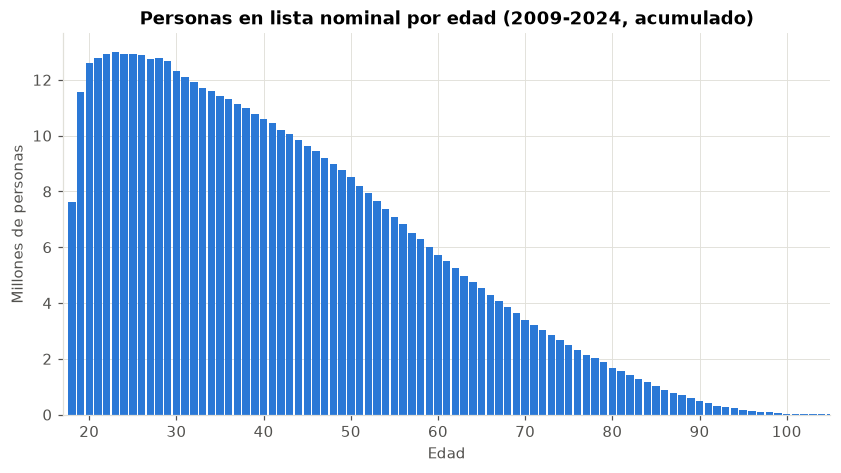

In [ ]:
fig, ax = plt.subplots()
ax.bar(ln_edad.index, ln_edad / 1e6, width=0.85, color=AZUL)
ax.set_title("Personas en lista nominal por edad (2009-2024, acumulado)")
ax.set_xlabel("Edad")
ax.set_ylabel("Millones de personas")
ax.set_xlim(17, 105)
plt.show()

## 15. Edades atípicas

Edades mayores a 100 años suelen ser registros desactualizados del padrón (personas fallecidas
no dadas de baja). Se cuantifican para decidir si se excluyen o se agrupan.

In [ ]:
for corte in [100, 110, 120]:
    sub = df[df["EDAD"] > corte]
    print(f"EDAD > {corte}: {len(sub):>9,} registros | {sub['LN'].sum():>9,} personas en LN | SV = {sub['SV'].sum():,}")

EDAD > 100:    91,629 registros |    94,090 personas en LN | SV = 9,439
EDAD > 110:     3,331 registros |     3,357 personas en LN | SV = 454
EDAD > 120:       371 registros |       373 personas en LN | SV = 91


## 16. Consistencia LN = SV + NV + NS

Cada persona en la lista nominal debe estar en exactamente una de las tres categorías.

In [ ]:
inconsistentes = (df["LN"] != df["SV"] + df["NV"] + df["NS"]).sum()
ln_cero = (df["LN"] == 0).sum()
print(f"Registros con LN != SV + NV + NS: {inconsistentes:,}")
print(f"Registros con LN = 0:             {ln_cero:,}")

Registros con LN != SV + NV + NS: 0
Registros con LN = 0:             0


## 17. No especificados (NS) por año

NS agrupa personas cuyo cuadernillo no estuvo disponible. Su peso cambia mucho entre elecciones,
por eso la participación se calcula sobre SV + NV y no sobre LN.

In [ ]:
totales = df.groupby("AELEC")[["LN", "SV", "NV", "NS"]].sum()
totales["pct_NS"] = totales["NS"] / totales["LN"] * 100
totales

,LN,SV,NV,NS,pct_NS
AELEC,,,,,
2009,77481831,33316974,42298963,1865894,2.41
2012,76490962,47383154,28939159,168649,0.22
2015,83563462,36926612,41517874,5118976,6.13
2018,89123997,51784399,31249856,6089742,6.83
2021,93532133,46389189,43099624,4043320,4.32
2024,98330348,54899228,37105466,6325654,6.43


## 18. Función de participación

% Participación = SV / (SV + NV), igual que en la plataforma CCPC.

In [ ]:
def participacion(datos, por):
    g = datos.groupby(por, observed=True)[["SV", "NV"]].sum()
    return g["SV"] / (g["SV"] + g["NV"]) * 100

## 19. Participación nacional por año

In [ ]:
part_ano = participacion(df, "AELEC").rename("participacion")
part_ano.to_frame()

,participacion
AELEC,
2009,44.06
2012,62.08
2015,47.07
2018,62.37
2021,51.84
2024,59.67


## 20. Gráfica: participación nacional por año

Se nota el patrón de las elecciones presidenciales (2012, 2018, 2024) frente a las intermedias
(2009, 2015, 2021).

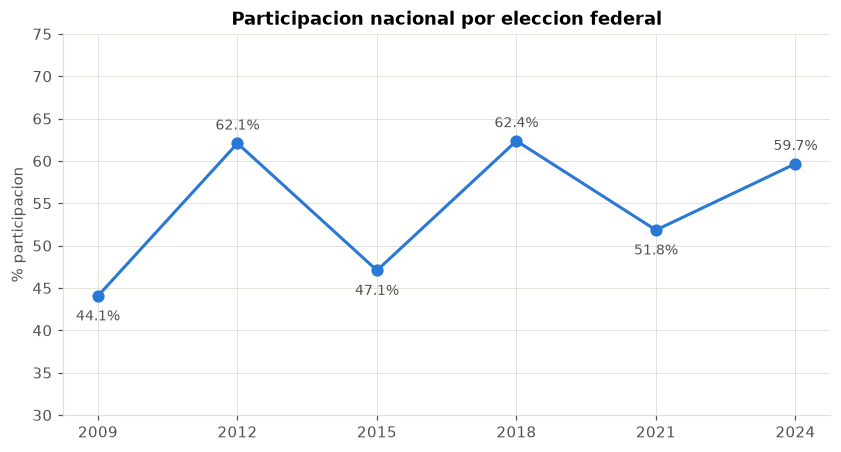

In [ ]:
fig, ax = plt.subplots()
ax.plot(part_ano.index, part_ano.values, marker="o", color=AZUL)
for x, y in part_ano.items():
    arriba = x in (2012, 2018, 2024)
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9 if arriba else -16),
                ha="center", color=TEXTO, fontsize=9)
ax.set_title("Participacion nacional por eleccion federal")
ax.set_ylabel("% participacion")
ax.set_xticks(part_ano.index)
ax.set_ylim(30, 75)
plt.show()

## 21. Participacion por sexo y año

Se excluye SEXO = 2 de la comparacion por su tamaño (sólo existe en 2024).

In [ ]:
part_sexo = participacion(df[df["SEXO"] < 2], ["AELEC", "SEXO"]).unstack()
part_sexo.columns = ["Hombre", "Mujer"]
part_sexo["brecha_M_H"] = part_sexo["Mujer"] - part_sexo["Hombre"]
part_sexo

,Hombre,Mujer,brecha_M_H
AELEC,,,
2009,40.53,47.35,6.82
2012,57.78,66.08,8.31
2015,42.95,50.89,7.94
2018,58.14,66.28,8.14
2021,47.76,55.62,7.86
2024,54.76,64.20,9.44


## 22. Gráfica: participación por sexo

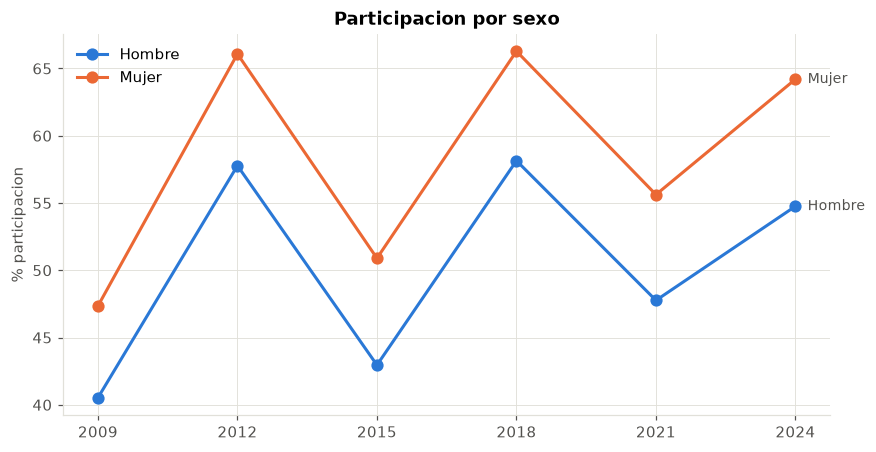

In [ ]:
fig, ax = plt.subplots()
for col, color in [("Hombre", AZUL), ("Mujer", NARANJA)]:
    ax.plot(part_sexo.index, part_sexo[col], marker="o", color=color, label=col)
    ax.annotate(col, (part_sexo.index[-1], part_sexo[col].iloc[-1]), textcoords="offset points",
                xytext=(8, 0), va="center", color=TEXTO, fontsize=9)
ax.set_title("Participacion por sexo")
ax.set_ylabel("% participacion")
ax.set_xticks(part_sexo.index)
ax.legend(frameon=False, loc="upper left")
plt.show()

## 23. Grupos de edad

Rangos usados en el resto del analisis. El ultimo grupo (80+) concentra las edades atípicas.

In [ ]:
CORTES = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

df["GRUPO_EDAD"] = pd.cut(df["EDAD"], bins=CORTES, labels=ETIQUETAS)
df.groupby("GRUPO_EDAD", observed=True)["LN"].sum().rename("personas_LN").to_frame()

,personas_LN
GRUPO_EDAD,
18-24,83478469
25-29,64052778
30-39,115320711
40-49,97212756
50-59,72425207
60-69,46612934
70-79,26056267
80+,13363611


## 24. Participación por grupo de edad y año

In [ ]:
part_edad = participacion(df, ["GRUPO_EDAD", "AELEC"]).unstack()
part_edad

AELEC,2009,2012,2015,2018,2021,2024
GRUPO_EDAD,,,,,,
18-24,37.16,55.70,38.08,54.76,43.96,50.40
25-29,34.45,52.41,35.01,52.89,39.65,47.25
30-39,39.86,58.18,43.01,59.94,45.60,53.93
40-49,48.63,67.35,51.49,66.33,54.90,62.10
50-59,54.84,72.24,57.01,70.47,61.42,68.28
60-69,57.86,73.84,62.13,73.04,66.78,74.57
70-79,53.96,69.48,60.18,70.09,65.78,73.81
80+,31.64,49.56,40.80,49.43,45.26,54.68


## 25. Gráfica: mapa de calor edad x año

Tono más oscuro = mayor participación.

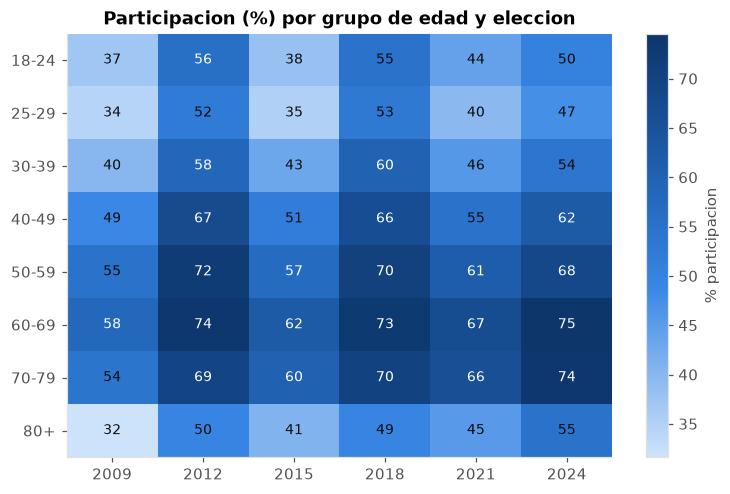

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(part_edad.values, cmap=CMAP_AZUL, aspect="auto")
ax.set_xticks(range(len(part_edad.columns)), part_edad.columns)
ax.set_yticks(range(len(part_edad.index)), part_edad.index)
ax.grid(False)
for i in range(part_edad.shape[0]):
    for j in range(part_edad.shape[1]):
        v = part_edad.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > part_edad.values.mean() else "#0b0b0b")
ax.set_title("Participacion (%) por grupo de edad y eleccion")
fig.colorbar(im, ax=ax, label="% participacion")
plt.show()

## 26. Participación por tipo de sección y año

In [ ]:
part_tiposec = participacion(df, ["TIPOSEC", "AELEC"]).unstack()
part_tiposec.index = part_tiposec.index.map({"U": "Urbana", "M": "Mixta", "R": "Rural"})
part_tiposec

AELEC,2009,2012,2015,2018,2021,2024
TIPOSEC,,,,,,
Mixta,44.63,61.35,48.42,61.39,52.20,57.94
Rural,48.09,64.18,54.50,64.68,58.40,60.11
Urbana,42.85,61.66,44.91,61.98,50.12,59.88


## 27. Participación por entidad (2024)

Ordenada de mayor a menor. Sirve para ubicar la variación regional antes de segmentar.

In [ ]:
df_2024 = df[df["AELEC"] == 2024]
part_edo = participacion(df_2024, "EDONOM").sort_values(ascending=False).rename("participacion")
part_edo.to_frame()

,participacion
EDONOM,
YUCATAN,71.45
TLAXCALA,70.09
CIUDAD DE MEXICO,69.31
COAHUILA,64.65
PUEBLA,64.27
MEXICO,63.85
HIDALGO,63.61
CAMPECHE,62.92
CHIAPAS,61.77


## 28. Gráfica: participación por entidad (2024)

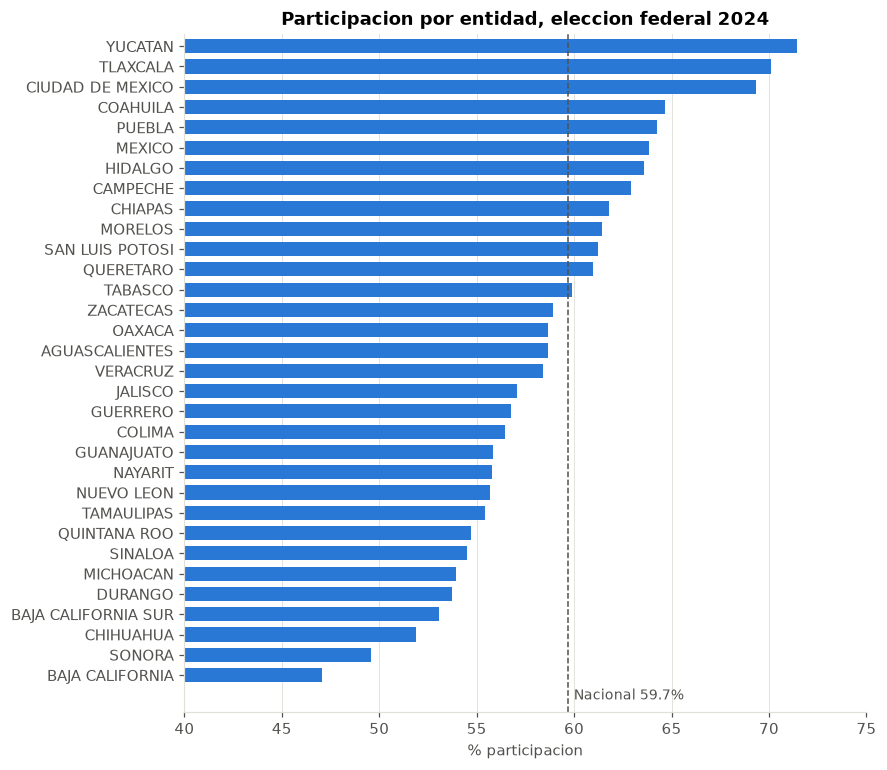

In [ ]:
orden = part_edo.sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(orden.index.astype(str), orden.values, color=AZUL, height=0.7)
ax.axvline(part_ano.loc[2024], color=TEXTO, linewidth=1, linestyle="--")
ax.annotate(f"Nacional {part_ano.loc[2024]:.1f}%", (part_ano.loc[2024], -1.2),
            xytext=(4, 0), textcoords="offset points", color=TEXTO, fontsize=9)
ax.set_ylim(-1.8, len(orden) - 0.4)
ax.set_title("Participacion por entidad, eleccion federal 2024")
ax.set_xlabel("% participacion")
ax.set_xlim(40, 75)
ax.grid(axis="y", visible=False)
plt.show()

## 29. Secciones presentes en todos los años

El historial de participación por sección requiere que la sección exista en las 6 elecciones.
Todos los años usan marco cartográfico DERFE 2021 salvo 2024 (DERFE 2023), asi que puede haber
secciones nuevas o dadas de baja.

In [ ]:
secciones = df[["AELEC", "EDOCVE", "SECCION"]].drop_duplicates()
anos_por_seccion = secciones.groupby(["EDOCVE", "SECCION"]).size()

print(f"Secciones distintas (entidad + seccion): {len(anos_por_seccion):,}")
print("\nNumero de elecciones en que aparece cada seccion:")
print(anos_por_seccion.value_counts().sort_index(ascending=False).to_string())
del secciones

Secciones distintas (entidad + seccion): 72,681

Numero de elecciones en que aparece cada seccion:
6    62048
5     3604
4     2658
3       81
2     1393
1     2897


## 30. Perfilado del dataset PJ 2025

Elección del Poder Judicial. Mismas medidas (LN, SV, NV, NS) a nivel sección x sexo x edad.

In [ ]:
df_pj = pd.read_parquet(PQ_PJ2025, columns=["EDOCVE", "TIPOSEC", "SEXO", "EDAD", "LN", "SV", "NV", "NS"])
print(f"Filas: {len(df_pj):,}")
print(f"Entidades: {df_pj['EDOCVE'].nunique()}")
print(f"Nulos: {df_pj.isna().sum().sum():,}")
print(f"LN != SV + NV + NS: {(df_pj['LN'] != df_pj['SV'] + df_pj['NV'] + df_pj['NS']).sum():,}")
print(f"\nTotales:\n{df_pj[['LN', 'SV', 'NV', 'NS']].sum().to_string()}")

Filas: 9,835,254
Entidades: 31
Nulos: 0
LN != SV + NV + NS: 0

Totales:
LN    99094375
SV    12720228
NV    85090368
NS     1283779


## 31. Participación PJ 2025 vs federal 2024 por grupo de edad

In [ ]:
df_pj["GRUPO_EDAD"] = pd.cut(df_pj["EDAD"], bins=CORTES, labels=ETIQUETAS)
comparacion = pd.DataFrame({
    "Federal 2024": participacion(df_2024, "GRUPO_EDAD"),
    "PJ 2025": participacion(df_pj, "GRUPO_EDAD"),
})
comparacion

,Federal 2024,PJ 2025
GRUPO_EDAD,,
18-24,50.40,7.93
25-29,47.25,7.81
30-39,53.93,10.02
40-49,62.10,12.99
50-59,68.28,16.04
60-69,74.57,21.65
70-79,73.81,22.14
80+,54.68,12.93


## 32. Gráfica: PJ 2025 vs federal 2024

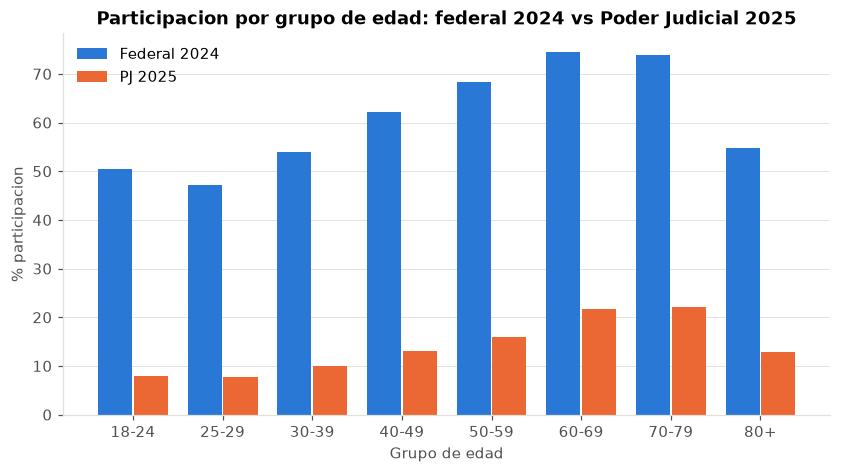

In [ ]:
x = range(len(comparacion))
fig, ax = plt.subplots()
ax.bar([i - 0.2 for i in x], comparacion["Federal 2024"], width=0.38, color=AZUL, label="Federal 2024")
ax.bar([i + 0.2 for i in x], comparacion["PJ 2025"], width=0.38, color=NARANJA, label="PJ 2025")
ax.set_xticks(list(x), comparacion.index)
ax.set_title("Participacion por grupo de edad: federal 2024 vs Poder Judicial 2025")
ax.set_xlabel("Grupo de edad")
ax.set_ylabel("% participacion")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.show()

## 33. Voto anticipado 2024

A diferencia de los conteos, cada fila es un voto individual (sin edad ni sección).

In [ ]:
df_va = pd.read_parquet(PQ_ANTICIPADO)
print(f"Votos: {len(df_va):,}")
print(f"Columnas: {list(df_va.columns)}")
print(f"\nPor sexo:\n{df_va['SEXO'].map({0: 'Hombre', 1: 'Mujer'}).value_counts().to_string()}")
print(f"\nTop 5 entidades:\n{df_va['EDONOM'].value_counts().head().to_string()}")

Votos: 3,449
Columnas: ['AELEC', 'EDOCVE', 'EDONOM', 'MPIOCVE', 'MPIONOM', 'DEF', 'DEL', 'SEXO']

Por sexo:
SEXO
Mujer     2143
Hombre    1306

Top 5 entidades:
EDONOM
CIUDAD DE MEXICO                   461
VERACRUZ DE IGNACIO DE LA LLAVE    221
JALISCO                            216
MEXICO                             196
AGUASCALIENTES                     169


## 34. Voto en prision preventiva 2024

También un registro por voto. La columna de entidad se llama `ESTADO` (no `EDOCVE`).

In [ ]:
df_pp = pd.read_parquet(PQ_PRISION)
print(f"Votos: {len(df_pp):,}")
print(f"Columnas: {list(df_pp.columns)}")
print(f"\nPor sexo:\n{df_pp['SEXO'].map({0: 'Hombre', 1: 'Mujer'}).value_counts().to_string()}")
print(f"\nTop 5 entidades:\n{df_pp['EDONOM'].value_counts().head().to_string()}")

Votos: 26,563
Columnas: ['AELEC', 'ESTADO', 'EDONOM', 'DEF', 'SEXO']

Por sexo:
SEXO
Hombre    24232
Mujer      2331

Top 5 entidades:
EDONOM
MEXICO              4719
JALISCO             2938
NUEVO LEON          1875
CIUDAD DE MEXICO    1799
PUEBLA              1560


## 35. Liberación de memoria

In [ ]:
del df, df_2024, df_pj, df_va, df_pp
gc.collect()
print("Memoria liberada.")

Memoria liberada.


## Resumen de hallazgos

**Calidad**

- Sin nulos en ningun dataset. `LN = SV + NV + NS` se cumple en el 100% de los registros (federal y PJ 2025).
- NS varia mucho por año (0.2% en 2012, 6.8% en 2018): la participación siempre se calcula sobre SV + NV.
- Edades atípicas: 94 mil personas con EDAD > 100 (0.01% de LN), con participación de ~10%. Se agrupan en 80+ o se excluyen.
- SEXO = 2 (no binario) sólo aparece en 2024 con 105 personas; no es analizable por separado.
- Los nombres de entidad no coinciden entre datasets (p. ej. `VERACRUZ` vs `VERACRUZ DE IGNACIO DE LA LLAVE`): unir por clave (`EDOCVE` / `ESTADO`), nunca por nombre.

**Cobertura**

- 32 entidades en todas las elecciones federales; PJ 2025 tiene 31.
- 72,681 secciones distintas; 62,048 (85%) aparecen en las 6 elecciones y permiten construir historial completo por sección.

**Patrones de participación**

- Ciclo electoral marcado: presidenciales (2012, 2018, 2024) ~60-62%, intermedias (2009, 2015, 2021) 44-52%.
- Las mujeres participan 7-9 puntos más que los hombres en todos los años; la brecha crece a 9.4 en 2024.
- Curva de edad en forma de U invertida: 25-29 es el grupo más bajo, el máximo está en 60-79 y cae en 80+.
- Lo rural participa más que lo urbano en intermedias (58 vs 50 en 2021); la diferencia casi desaparece en presidenciales.
- Variación regional de 24 puntos en 2024: Yucatan 71% vs Baja California 47%; el norte del país esta por debajo del promedio.
- PJ 2025 tuvo 13% de participación, con el mismo gradiente por edad que las federales pero mucho más pronunciado.
- Voto anticipado (3,449 votos) es mayoritariamente femenino (62%); prisión preventiva (26,563) es 91% masculino.

**Implicaciones para la segmentacion**

- Variables con más poder discriminante: edad, sexo, region y tipo de seccion, más la diferencia presidencial vs intermedia.
- La unidad natural para el historial es la sección (o sección x sexo x grupo de edad) en las 62 mil secciones con 6 elecciones.